# Práctica 5: Manuel Alejandro Serrano Macias
# W2V en tuits

In [36]:
def get_texts_from_file(path_corpus, path_truth):
  tr_txt = []
  tr_y = []

  with open(path_corpus, "r", encoding="utf-8") as f_corpus, open (path_truth, "r", encoding="utf-8") as f_truth:

    for twitt in f_corpus:
      tr_txt += [twitt]
    
    for label in f_truth:
      tr_y += [label]

  return tr_txt, tr_y

In [37]:
tr_txt, tr_y = get_texts_from_file("./mex20_train.txt","./mex20_train_labels.txt")

Counter({'0\n': 3759, '1\n': 1519})


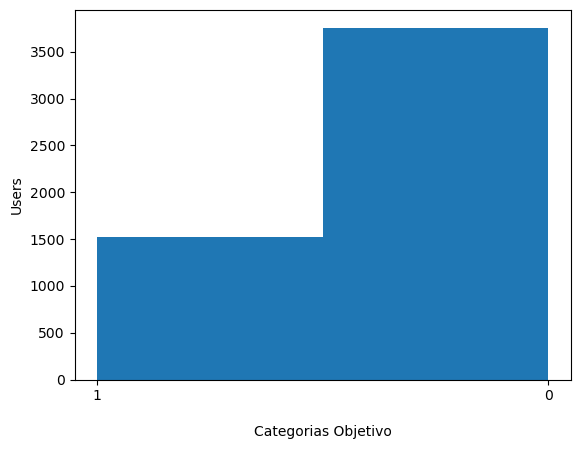

In [38]:
from collections import Counter
import matplotlib.pyplot as plt
%matplotlib inline

print(Counter(tr_y))
plt.hist(tr_y, bins=len(set(tr_y)))
plt.ylabel("Users")
plt.xlabel("Categorias Objetivo")
plt.show()

In [39]:
import nltk
from nltk.tokenize import TweetTokenizer

tokenizer = TweetTokenizer()
corpus_palabras = []
for doc in tr_txt:
  corpus_palabras += [tokenizer.tokenize(doc.lower())]

In [40]:
from gensim.models import Word2Vec

In [41]:
sentences = corpus_palabras
model = Word2Vec(sentences, vector_size = 50, window = 10, min_count = 1, workers = 1)

In [42]:
model.wv['madre']

array([ 0.13180162,  0.36897978, -0.19575866,  0.58016115, -0.2996314 ,
       -1.1186037 ,  2.166215  ,  2.5247087 , -2.5209136 , -1.2832158 ,
       -0.128581  , -2.681495  ,  1.3484437 ,  1.0041804 , -0.4547077 ,
        1.58181   ,  1.6457456 ,  0.51052177, -1.9440488 , -2.0301151 ,
        0.5850525 ,  1.8197237 ,  3.2581189 , -0.35199103,  0.84564173,
        1.3371174 , -0.48247713,  0.3822999 , -0.66214055,  0.29611912,
       -0.08316702, -1.2949463 ,  0.7274372 , -0.69169945, -1.0935578 ,
        0.8980708 ,  1.3771554 , -0.15430965,  0.8742168 , -0.03732725,
        2.3612413 , -0.3182022 , -0.711215  ,  0.4912602 ,  2.9213743 ,
        0.37763956, -0.21508512, -1.4407959 ,  0.962447  ,  0.55401886],
      dtype=float32)

In [43]:
model.wv.most_similar('hdp')

[('puto', 0.9997231960296631),
 ('pinche', 0.9996017217636108),
 ('mamar', 0.9995073676109314),
 ('..', 0.9994463920593262),
 ('esa', 0.9993484616279602),
 ('este', 0.99925696849823),
 ('eso', 0.9991624355316162),
 ('🙄', 0.9991388916969299),
 ('méxico', 0.9991222620010376),
 ('putos', 0.9991187453269958)]

In [44]:
model.wv.most_similar('😠')

[('maricón', 0.9968912601470947),
 ('hdp', 0.9968613386154175),
 ('pinche', 0.9967156052589417),
 ('mamar', 0.9966406226158142),
 ('méxico', 0.9966355562210083),
 ('puto', 0.996466875076294),
 ('hijos', 0.9964326620101929),
 ('😤', 0.9964202046394348),
 ('poca', 0.996320366859436),
 ('rt', 0.9963036775588989)]

In [45]:
model.wv.most_similar('🤣')

[('😂', 0.9907774925231934),
 ('😀', 0.9548690319061279),
 ('prro', 0.9359164237976074),
 ('👋🏼', 0.933476984500885),
 ('😁', 0.9308459758758545),
 ('jajajajajaja', 0.9291518926620483),
 ('sales', 0.9247382879257202),
 ('estuve', 0.9226486682891846),
 ('🤦🏻\u200d♀', 0.9217528104782104),
 ('hablas', 0.9213235378265381)]

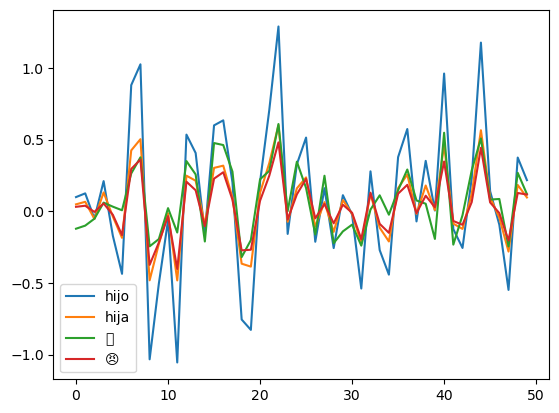

In [46]:
plt.plot(model.wv['hijo'][:50], label='hijo')
plt.plot(model.wv['hija'][:50], label='hija')
plt.plot(model.wv['🤣'][:50], label='🤣')
plt.plot(model.wv['😠'][:50], label='😠')
plt.legend()
plt.show()

In [47]:
model.wv.most_similar(positive=['jajaja', 'hdp'])

[('puto', 0.9997616410255432),
 ('pinche', 0.999650239944458),
 ('..', 0.9996369481086731),
 ('esa', 0.9996134638786316),
 ('ese', 0.9996020793914795),
 ('🙄', 0.9995464086532593),
 ('...', 0.9995402097702026),
 ('ahora', 0.9995290040969849),
 ('luchona', 0.9995198845863342),
 ('mamar', 0.9994845390319824)]

In [48]:
model.wv.most_similar(positive=['perro', '🤣'])

[('jajajajajaja', 0.9905487895011902),
 ('😁', 0.9899207949638367),
 ('🤦🏻\u200d♀', 0.9861875176429749),
 ('hablas', 0.985080897808075),
 ('🙃', 0.9835612177848816),
 ('berga', 0.981240451335907),
 ('👌', 0.9801152944564819),
 ('adiós', 0.9797353148460388),
 ('regreso', 0.9772149324417114),
 ('mundial', 0.9767841100692749)]

In [49]:
model.wv.most_similar(positive=['madre'])

[('hijo', 0.9993073344230652),
 ('tu', 0.9992684125900269),
 ('puta', 0.9991807341575623),
 ('su', 0.9991251826286316),
 ('pendejo', 0.9990671277046204),
 ('hijos', 0.9990093111991882),
 ('pinche', 0.9988764524459839),
 ('puto', 0.9986984729766846),
 ('mierda', 0.9986075758934021),
 ('méxico', 0.9985494613647461)]

In [50]:
model.wv.most_similar(positive=['padre'])

[('vez', 0.9968176484107971),
 ('tu', 0.9966870546340942),
 ('d', 0.9966391921043396),
 ('chiflar', 0.9966371655464172),
 ('ven', 0.9965986013412476),
 ('2', 0.9965726733207703),
 ('méxico', 0.9965628981590271),
 ('*', 0.9965613484382629),
 ('su', 0.9965258240699768),
 ('ser', 0.996402382850647)]

In [51]:
model.wv.most_similar(positive=['😠', '🤣'])

[('😁', 0.9898809194564819),
 ('jajajajajaja', 0.9881384968757629),
 ('🤦🏻\u200d♀', 0.9861078262329102),
 ('hablas', 0.9842243790626526),
 ('🙃', 0.9839115738868713),
 ('berga', 0.9813834428787231),
 ('👌', 0.979438841342926),
 ('regreso', 0.9781266450881958),
 ('adiós', 0.9778409004211426),
 ('️', 0.9774558544158936)]

In [52]:
model.wv.most_similar(positive=['🤦🏻'])

[('empiezo', 0.9626036882400513),
 ('haga', 0.9581825733184814),
 ('lentes', 0.9576425552368164),
 ('usar', 0.9570802450180054),
 ('fuerte', 0.9570039510726929),
 ('estado', 0.9568593502044678),
 ('visto', 0.9567593932151794),
 ('poner', 0.9566499590873718),
 ('😜', 0.9565868377685547),
 ('hagan', 0.9563500881195068)]